# Kalshi vs. Polymarket — Full 9-Event Pull

This notebook downloads price history for all 9 matched events, lines up
Kalshi and Polymarket prices in time, computes the gap for each event,
flags outlier points, saves a CSV per event, and plots prices + gap.

**Before running:** fill in the `EVENTS` table below with the real
Kalshi ticker and Polymarket token ID for each event. Use
`find-kalshi` / `find-polymarket` style lookups (cells further down)
to get these values if you don't have them yet.


In [1]:
# Install what we need
!pip install requests pandas matplotlib -q

In [2]:
import json
import requests
import pandas as pd
from pathlib import Path
from datetime import datetime, timezone, timedelta
import matplotlib.pyplot as plt

KALSHI_BASES = (
    "https://trading-api.kalshi.com/trade-api/v2",
    "https://api.elections.kalshi.com/trade-api/v2",
    "https://external-api.kalshi.com/trade-api/v2",
)

KALSHI_MAX_CANDLES_PER_REQUEST = 5000
KALSHI_ALLOWED_PERIODS_MINUTES = (1, 60, 1440)

POLY_GAMMA_BASE = "https://gamma-api.polymarket.com"
POLY_CLOB_BASE = "https://clob.polymarket.com"

POLY_MAX_WINDOW_DAYS = 14

# Use hourly observations for now
DEFAULT_PERIOD_MINUTES = 60
DEFAULT_POLY_FIDELITY_MINUTES = 60

In [3]:
def to_unix_start(date_str):
    return int(
        datetime.strptime(date_str, "%Y-%m-%d")
        .replace(tzinfo=timezone.utc)
        .timestamp()
    )


def to_unix_end(date_str):
    dt = (
        datetime.strptime(date_str, "%Y-%m-%d")
        .replace(tzinfo=timezone.utc)
    )
    return int(
        (dt + timedelta(days=1) - timedelta(seconds=1)).timestamp()
    )


def find_kalshi_markets(series_ticker):
    rows = []
    seen = set()

    for historical in (False, True):
        cursor = None

        for _ in range(50):
            params = {
                "series_ticker": series_ticker,
                "limit": 1000
            }

            if cursor:
                params["cursor"] = cursor

            if historical:
                path = "/historical/markets"
            else:
                path = "/markets"

            response = None

            for base in KALSHI_BASES:
                try:
                    r = requests.get(
                        f"{base}{path}",
                        params=params,
                        timeout=30
                    )
                except requests.RequestException:
                    continue

                if r.status_code == 200:
                    response = r
                    break

            if response is None:
                break

            body = response.json()

            for m in body.get("markets", []):
                ticker = m.get("ticker")

                if ticker and ticker not in seen:
                    seen.add(ticker)

                    rows.append({
                        "ticker": ticker,
                        "title": m.get("title"),
                        "yes_sub_title": m.get("yes_sub_title"),
                        "status": m.get("status"),
                        "close_time": m.get("close_time"),
                        "result": m.get("result"),
                        "source": "historical" if historical else "live",
                    })

            cursor = body.get("cursor")

            if not cursor:
                break

    return pd.DataFrame(rows)


def _parse_json_list(value):
    if isinstance(value, list):
        return value

    if isinstance(value, str):
        try:
            value = json.loads(value)
        except:
            return []

    return value if isinstance(value, list) else []


def find_polymarket_event(slug_or_query):

    url = f"{POLY_GAMMA_BASE}/events"

    attempts = [
        {"slug": slug_or_query, "closed": "true", "limit": 100},
        {"search": slug_or_query, "closed": "true", "limit": 100},
        {"slug": slug_or_query, "limit": 100},
        {"search": slug_or_query, "limit": 100},
    ]

    events = []

    for params in attempts:
        try:
            r = requests.get(url, params=params, timeout=30)
        except requests.RequestException:
            continue

        if r.status_code == 200 and r.json():
            events = r.json()
            break

    rows = []

    for ev in events:
        for m in ev.get("markets", []):

            tokens = _parse_json_list(m.get("clobTokenIds"))
            outcomes = _parse_json_list(m.get("outcomes"))

            token_by_outcome = (
                dict(zip(outcomes, tokens))
                if len(outcomes) == len(tokens)
                else {}
            )

            rows.append({
                "event_slug": ev.get("slug"),
                "market_question": m.get("question"),
                "yes_token_id": token_by_outcome.get(
                    "Yes",
                    tokens[0] if tokens else None
                ),
                "no_token_id": token_by_outcome.get(
                    "No",
                    tokens[1] if len(tokens) > 1 else None
                ),
                "closed": m.get("closed"),
                "end_date": m.get("endDate"),
            })

    return pd.DataFrame(rows)


def resolve_polymarket_yes_token(event_slug, market_contains):

    df = find_polymarket_event(event_slug)

    if df.empty:
        return None

    mask = (
        df["market_question"]
        .fillna("")
        .str.contains(market_contains, case=False, regex=False)
    )

    matches = df[mask]

    if len(matches) != 1:
        print(f"Found {len(matches)} matches:")
        print(matches[["market_question", "yes_token_id"]])
        return None

    return str(matches.iloc[0]["yes_token_id"])

In [4]:
def _as_probability(value):
    if value in (None, ""):
        return None

    try:
        x = float(value)
    except:
        return None

    # Kalshi can give cents like 65 instead of 0.65
    return x / 100 if x > 1 else x


def _close_from_block(block):
    block = block or {}

    value = block.get("close_dollars")

    if value in (None, ""):
        value = block.get("close")

    return _as_probability(value)


def _kalshi_candles_to_df(candles):

    rows = []

    for c in candles:

        trade = _close_from_block(c.get("price"))
        bid = _close_from_block(c.get("yes_bid"))
        ask = _close_from_block(c.get("yes_ask"))

        # Prefer bid/ask midpoint when available
        if bid is not None and ask is not None:
            price = (bid + ask) / 2
            source = "midpoint"
        else:
            price = trade
            source = "last_trade"

        if price is None:
            continue

        rows.append({
            "timestamp": pd.to_datetime(
                c["end_period_ts"],
                unit="s",
                utc=True
            ),
            "price": float(price),
            "volume": pd.to_numeric(
                c.get("volume_fp", c.get("volume")),
                errors="coerce"
            ),
            "price_source": source,
        })

    return pd.DataFrame(rows)


def get_kalshi_candles(
    ticker,
    start,
    end,
    period_minutes=DEFAULT_PERIOD_MINUTES
):

    series_ticker = ticker.split("-")[0]

    start_ts = to_unix_start(start)
    end_ts = to_unix_end(end)

    seconds_per_request = (
        KALSHI_MAX_CANDLES_PER_REQUEST
        * period_minutes
        * 60
    )

    chunks = []

    cur = start_ts

    while cur <= end_ts:

        c_end = min(
            cur + seconds_per_request - 1,
            end_ts
        )

        chunks.append((cur, c_end))

        cur = c_end + 1

    frames = []

    for c_start, c_end in chunks:

        params = {
            "start_ts": c_start,
            "end_ts": c_end,
            "period_interval": period_minutes
        }

        endpoints = []

        for base in KALSHI_BASES:

            # live endpoint
            endpoints.append(
                (
                    base,
                    f"/series/{series_ticker}/markets/"
                    f"{ticker}/candlesticks"
                )
            )

            # historical endpoint
            endpoints.append(
                (
                    base,
                    f"/historical/markets/"
                    f"{ticker}/candlesticks"
                )
            )

        got = False

        for base, path in endpoints:

            try:
                r = requests.get(
                    f"{base}{path}",
                    params=params,
                    timeout=30
                )
            except requests.RequestException:
                continue

            if r.status_code != 200:
                continue

            candles = r.json().get("candlesticks", [])

            if candles:

                frame = _kalshi_candles_to_df(candles)

                if not frame.empty:
                    frames.append(frame)
                    got = True
                    break

        if not got:
            print(
                f"No Kalshi data for "
                f"{ticker} [{c_start}, {c_end}]"
            )

    if not frames:
        return pd.DataFrame(
            columns=[
                "timestamp",
                "price",
                "volume",
                "price_source"
            ]
        )

    out = pd.concat(frames, ignore_index=True)

    out = (
        out
        .drop_duplicates("timestamp")
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    print(
        f"Kalshi: {len(out)} observations"
    )

    return out

In [5]:
# ============================================================
# DOWNLOAD: Polymarket price history (chunked, with granularity cascade)
# ============================================================

def _fetch_one_polymarket_chunk(
    token_id,
    c_start,
    c_end,
    fidelity_minutes=DEFAULT_POLY_FIDELITY_MINUTES
):

    params = {
        "market": str(token_id),
        "startTs": int(c_start),
        "endTs": int(c_end),
        "fidelity": int(fidelity_minutes),
    }

    r = requests.get(
        f"{POLY_CLOB_BASE}/prices-history",
        params=params,
        timeout=30
    )

    if r.status_code != 200:

        print(
            "Polymarket error:",
            r.status_code,
            r.text[:200]
        )

        return pd.DataFrame(
            columns=["timestamp", "price"]
        )

    rows = r.json().get("history", [])

    if not rows:
        return pd.DataFrame(
            columns=["timestamp", "price"]
        )

    df = pd.DataFrame(rows)

    df["timestamp"] = pd.to_datetime(
        df["t"],
        unit="s",
        utc=True
    )

    df["price"] = pd.to_numeric(
        df["p"],
        errors="coerce"
    )

    return (
        df[["timestamp", "price"]]
        .dropna()
    )


def get_polymarket_history(
    token_id,
    start,
    end,
    fidelity_minutes=DEFAULT_POLY_FIDELITY_MINUTES
):

    start_ts = to_unix_start(start)
    end_ts = to_unix_end(end)

    window_seconds = (
        POLY_MAX_WINDOW_DAYS * 86400
    )

    chunks = []

    cur = start_ts

    while cur <= end_ts:

        c_end = min(
            cur + window_seconds - 1,
            end_ts
        )

        chunks.append(
            (cur, c_end)
        )

        cur = c_end + 1

    frames = []

    for c_start, c_end in chunks:

        frame = _fetch_one_polymarket_chunk(
            token_id,
            c_start,
            c_end,
            fidelity_minutes
        )

        if not frame.empty:
            frames.append(frame)

    if not frames:

        print(
            f"No Polymarket data "
            f"for token {token_id}"
        )

        return pd.DataFrame(
            columns=["timestamp", "price"]
        )

    out = pd.concat(
        frames,
        ignore_index=True
    )

    out = (
        out
        .drop_duplicates("timestamp")
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    print(
        f"Polymarket: {len(out)} observations"
    )

    return out


In [6]:
# ============================================================
# ALIGN: pair up both series by nearest timestamp (never fake values)
# ============================================================

def align_and_compute_gap(kalshi_df, poly_df, tolerance="30min"):
    """
    Pair Kalshi and Polymarket prices at matching moments.
    Each Polymarket point is matched to the nearest Kalshi point within
    `tolerance`. If nothing is close enough, that point is dropped, not faked.
    gap = kalshi_price - polymarket_price.
    """
    if kalshi_df.empty or poly_df.empty:
        print("Cannot align: one or both series are empty.")
        return pd.DataFrame()

    k = kalshi_df[["timestamp", "price"]].sort_values("timestamp").rename(columns={"price": "kalshi"})
    p = poly_df[["timestamp", "price"]].sort_values("timestamp").rename(columns={"price": "polymarket"})

    merged = pd.merge_asof(p, k, on="timestamp", direction="nearest", tolerance=pd.Timedelta(tolerance))
    merged = merged.dropna(subset=["kalshi", "polymarket"])
    merged["gap"] = merged["kalshi"] - merged["polymarket"]
    return merged.reset_index(drop=True)


In [7]:
# ============================================================
# FLAG: mark gap points that look like outliers vs. their close neighbors
# ============================================================

def flag_gap_outliers(merged_df, window_size=11, z_score_threshold=5.0):
    """
    For each point, compare it to the median of its 11 nearest neighbors,
    using MAD (median absolute deviation) instead of standard deviation
    so one big spike doesn't hide itself by inflating the threshold.
    Flags a point if it's more than z_score_threshold MAD-units away.
    This flags "looks structurally unusual," not "confirmed bad data."
    """
    if merged_df.empty or "gap" not in merged_df.columns:
        return merged_df

    gap = merged_df["gap"]
    rolling_median = gap.rolling(window_size, center=True, min_periods=3).median()
    rolling_mad = (gap - rolling_median).abs().rolling(window_size, center=True, min_periods=3).median()
    z = 0.6745 * (gap - rolling_median) / rolling_mad.replace(0, pd.NA)

    result = merged_df.copy()
    result["gap_zscore"] = z
    result["is_outlier"] = z.abs() > z_score_threshold
    n_flagged = int(result["is_outlier"].sum())
    if n_flagged:
        print(f"  flagged {n_flagged} outlier point(s)")
    return result


In [8]:
# ============================================================
# PLOT: prices on top, gap on bottom, outliers marked in red
# ============================================================

def plot_gap(merged_df, output_path, title):
    fig, (price_ax, gap_ax) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

    price_ax.plot(merged_df["timestamp"], merged_df["kalshi"], label="Kalshi")
    price_ax.plot(merged_df["timestamp"], merged_df["polymarket"], label="Polymarket")
    price_ax.set_ylabel("Implied probability")
    price_ax.set_title(title)
    price_ax.legend()

    gap_ax.plot(merged_df["timestamp"], merged_df["gap"], color="black")
    gap_ax.axhline(0, color="gray", linewidth=0.8)
    if "is_outlier" in merged_df.columns and merged_df["is_outlier"].any():
        flagged = merged_df[merged_df["is_outlier"]]
        gap_ax.scatter(flagged["timestamp"], flagged["gap"], color="red", marker="x", s=60, zorder=5, label="flagged outlier")
        gap_ax.legend()
    gap_ax.set_ylabel("Gap (Kalshi - Poly)")
    gap_ax.set_xlabel("Time (UTC)")

    fig.tight_layout()
    fig.savefig(output_path, dpi=150)
    plt.show()
    print(f"Saved plot to {output_path}")


## Step 1 (optional) — look up tickers/tokens you don't have yet

Run these for any event where you still need the exact Kalshi ticker or
Polymarket token ID. Skip this cell for events you've already filled in below.


In [9]:
find_kalshi_markets("kxnextpope-35")

""


In [10]:
find_polymarket_event("will-robert-francis-prevost-be-the-next-pope")

,event_slug,market_question,yes_token_id,no_token_id,closed,end_date
0,nba-will-the-mavericks-beat-the-grizzlies-by-m...,NBA: Will the Mavericks beat the Grizzlies by ...,2818240400596794065249546322853784090105564972...,4704484575345002204743642996880860113081116413...,True,2021-12-04T00:00:00Z
1,nfl-will-the-falcons-beat-the-panthers-by-more...,NFL: Will the Falcons beat the Panthers by mor...,5651125965385588665993682796678601354578484114...,1494147829524460538210005523592414355921862857...,True,2021-10-31T00:00:00Z
2,in-game-trading-will-the-49ers-beat-the-packer...,(In-Game Trading) Will the 49ers beat the Pack...,4104067668795859615384489396131116098733722382...,9685007407620063215857460980993871981836925299...,True,2021-09-26T00:00:00Z
3,2022-norway-chess-will-magnus-carlsen-lose-any...,2022 Norway Chess: Will Magnus Carlsen lose an...,1401226592564766987759197710371883009905119883...,5942112641947195188739818795985678938024517492...,True,2022-06-11T00:00:00Z
4,nba-will-the-heat-beat-the-wizards-by-more-tha...,NBA: Will the Heat beat the Wizards by more th...,4602187693317718142253571211798817444074245219...,9452629381789550631136729140395189928744241523...,True,2021-11-18T00:00:00Z
...,...,...,...,...,...,...
95,in-game-trading-will-washington-beat-the-atlan...,(In-Game Trading) Will Washington beat the Atl...,8905933392047686686095204515649469823132019726...,9954908197578251953485150612875860836696547211...,True,2021-10-03T00:00:00Z
96,will-japan-or-the-usa-win-the-baseball-gold-me...,Will Japan or the USA win gold in Baseball at ...,1769155006039598554439190641176989319782049304...,4778727528273374332748714851754844732892817439...,True,2021-08-07T00:00:00Z
97,will-the-wormhole-hacker-return-69-or-more-of-...,Will the Wormhole hacker return 69% or more of...,6812016453364526697856674809988423821618784825...,7968046389967344337608558176941419599873315396...,True,2022-02-09T00:00:00Z
98,will-fully-vaccinated-non-essential-canadian-t...,Will fully vaccinated non-essential Canadian t...,5672091305937165140749534401014315707100271042...,3397389898828316075619821456353111536589719298...,True,2021-09-01T00:00:00Z


In [11]:
token = resolve_polymarket_yes_token(
    "world-series-champion-2025",
    "Los Angeles Dodgers"
)

print(token)

50056291296373013403053264672448796961558656386670931029485176637893947669174


In [12]:
token = resolve_polymarket_yes_token(
    "nba-champion-2024-2025",
    "Oklahoma City Thunder"
)

print(token)

83527644927648970835156950007024690327726158617181889316317174894904268227846


In [13]:
token = resolve_polymarket_yes_token(
    "who-will-be-the-next-pope",
    "Robert Francis Prevost"
)

print(token)

113845724700054083561790691604568760899627369924969834963221702983533500982036


In [14]:
token = resolve_polymarket_yes_token(
    "oscars-best-picture",
    "Anora"
)

print(token)

1018044885195187396947687732754809918865343613107923057688573272106246886316


In [15]:
token = resolve_polymarket_yes_token(
    "taylor-swift-and-travis-kelce-engaged-in-2025",
    "Taylor Swift and Travis Kelce engaged"
)

print(token)

65243545140060488194767449391633027630960354524222035359867983913384312052417


## Step 2 — fill in all 9 events here

Replace every `"FILL_IN"` with the real ticker / token ID / date range.
`category` and `label` are just for organizing output files and plots.


In [16]:
EVENTS = [
    # --- Politics ---
    {
        "label": "election_2024_DJT_wins",
        "category": "Politics",
        "kalshi_ticker": "PRES-2024-DJT",
        "poly_token_id": "21742633143463906290569050155826241533067272736897614950488156847949938836455",
        "start": "2024-10-01", "end": "2024-11-06",
    },
    {
        "label": "fomc_sep2026_hike_25bp",
        "category": "Politics",
        "kalshi_ticker": "KXFEDDECISION-26SEP-H25",
        "poly_token_id": "63842529068710005716169325380315470359047749786610778647370693404952498013178",
        "start": "2026-08-15", "end": "2026-09-17",
    },
    {
        "label": "shutdown_oct2025_yes",
        "category": "Politics",
        "kalshi_ticker": "KXGOVSHUT-25OCT01",
        "poly_token_id": "98045093822431547938365423095786421804452886266888528428746910959667685407691",
        "start": "2025-09-01", "end": "2025-10-02",
    },
    # --- Sports ---
    {
        "label": "super_bowl_lx_seattle_wins",
        "category": "Sports",
        "kalshi_ticker": "KXSB-26-SEA",
        "poly_token_id": "91737931954079461205792748723730956466398437395923414328893692961489566016241",
        "start": "2026-01-01", "end": "2026-02-10",
    },
    {
        "label": "world_series_2025_dodgers_win",
        "category": "Sports",
        "kalshi_ticker": "KXMLB-25-LAD",
        "poly_token_id": "50056291296373013403053264672448796961558656386670931029485176637893947669174",
        "start": "2025-10-01", "end": "2025-11-05",
    },
    {
        "label": "nba_finals_2025_okc_win",
        "category": "Sports",
        "kalshi_ticker": "KXNBA-25-OKC",
        "poly_token_id": "83527644927648970835156950007024690327726158617181889316317174894904268227846",
        "start": "2025-05-15", "end": "2025-06-25",
    },
    # --- Culture ---
    {
        "label": "papal_conclave_2025_prevost",
        "category": "Culture",
        "kalshi_ticker": "KXNEXTPOPE-35-RPRE",
        "poly_token_id": "113845724700054083561790691604568760899627369924969834963221702983533500982036",
        "start": "2025-04-15", "end": "2025-05-10",
    },
    {
        "label": "oscars_2025_anora_best_pic",
        "category": "Culture",
        "kalshi_ticker": "KXOSCARPIC-25-A",
        "poly_token_id": "1018044885195187396947687732754809918865343613107923057688573272106246886316",
        "start": "2025-02-01", "end": "2025-03-03",
    },
    {
        "label": "taylor_swift_engagement_yes",
        "category": "Culture",
        "kalshi_ticker": "KXENGAGEMENTSWIFTKELCE-25",
        "poly_token_id": "65243545140060488194767449391633027630960354524222035359867983913384312052417",
        "start": "2025-07-15", "end": "2025-08-27",
    },
]

print(f"{len(EVENTS)} events configured.")


9 events configured.


In [17]:
def resolve_event_ids(event):

    e = dict(event)

    if (
        e.get("poly_token_id") == "FILL_IN"
        and e.get("poly_event_slug")
        and e.get("poly_market_contains")
    ):

        print(
            f"Resolving Polymarket token "
            f"for {e['label']}..."
        )

        token = resolve_polymarket_yes_token(
            e["poly_event_slug"],
            e["poly_market_contains"]
        )

        if token:
            e["poly_token_id"] = token
            print("Found:", token)

    return e

## Step 3 — run the full pull for every event

For each event: download both series, align them, flag outliers, save a
CSV, and save + show a plot. Events with `"FILL_IN"` still in them are
skipped automatically, with a warning, so you can fill them in gradually.



=== election_2024_DJT_wins (Politics) ===
Kalshi: 618 observations
Polymarket: 880 observations
Aligning markets...
  flagged 25 outlier point(s)


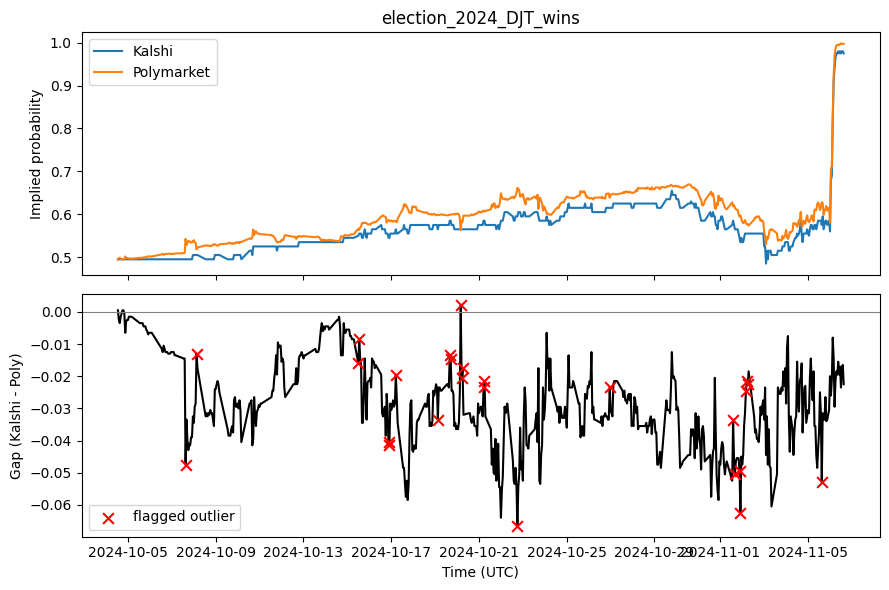

Saved plot to out/election_2024_DJT_wins/gap_plot.png
Done: 609 matched observations

=== fomc_sep2026_hike_25bp (Politics) ===
Kalshi: 779 observations
Polymarket: 789 observations
Aligning markets...
  flagged 11 outlier point(s)


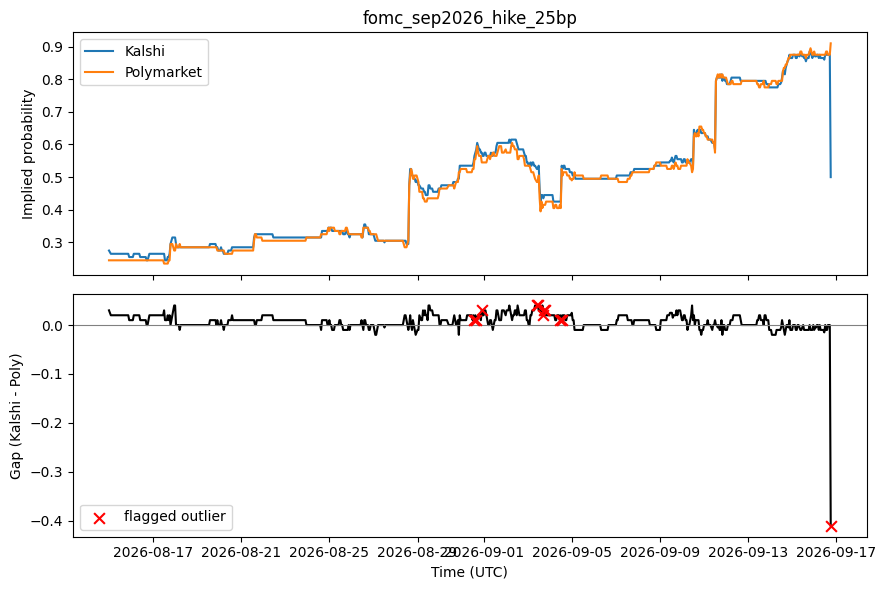

Saved plot to out/fomc_sep2026_hike_25bp/gap_plot.png
Done: 778 matched observations

=== shutdown_oct2025_yes (Politics) ===
Kalshi: 372 observations
Polymarket: 700 observations
Aligning markets...
  flagged 4 outlier point(s)


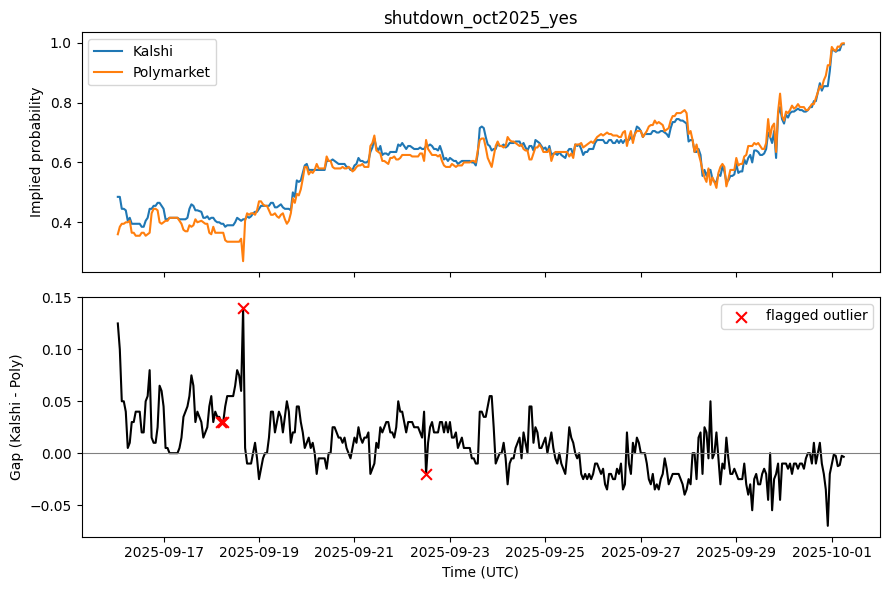

Saved plot to out/shutdown_oct2025_yes/gap_plot.png
Done: 362 matched observations

=== super_bowl_lx_seattle_wins (Sports) ===
Kalshi: 939 observations
Polymarket: 930 observations
Aligning markets...
  flagged 12 outlier point(s)


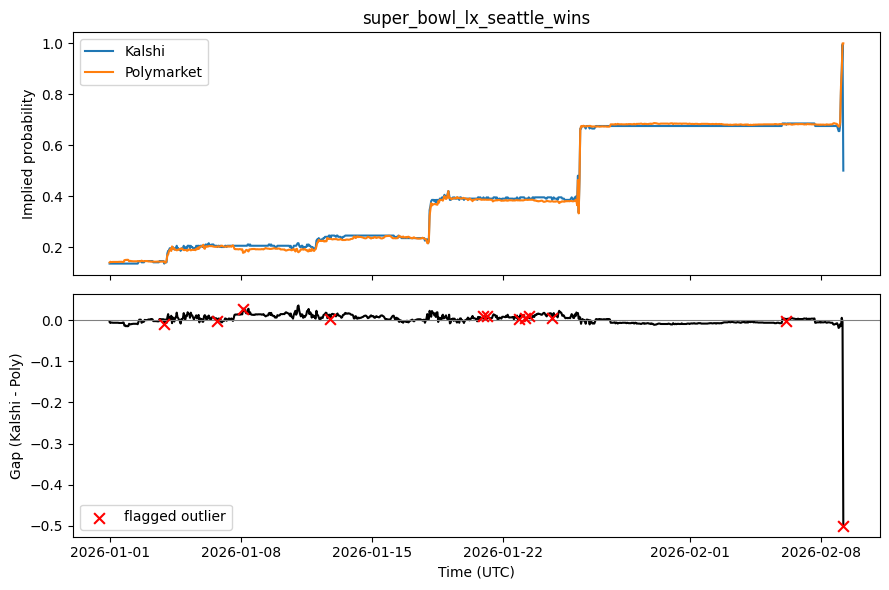

Saved plot to out/super_bowl_lx_seattle_wins/gap_plot.png
Done: 925 matched observations

=== world_series_2025_dodgers_win (Sports) ===
Kalshi: 769 observations
Polymarket: 772 observations
Aligning markets...
  flagged 22 outlier point(s)


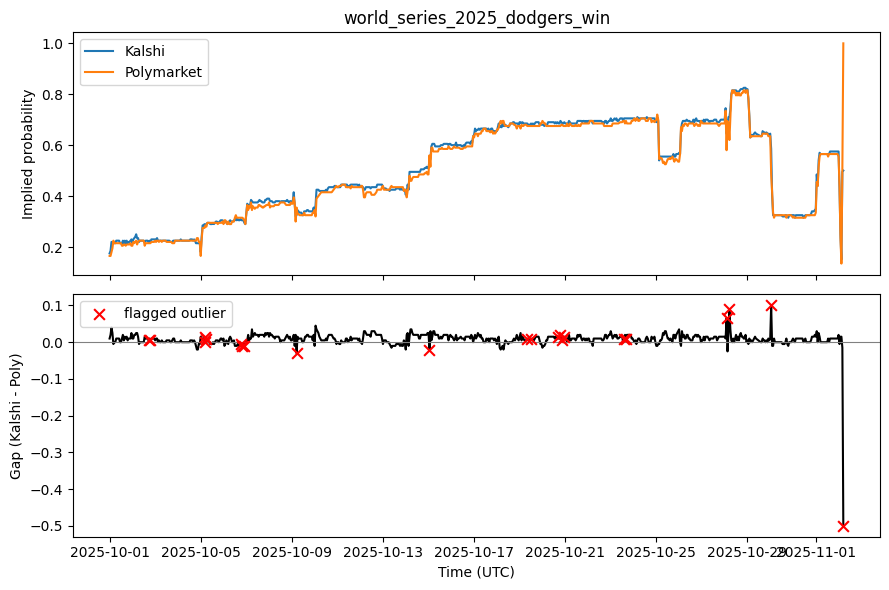

Saved plot to out/world_series_2025_dodgers_win/gap_plot.png
Done: 765 matched observations

=== nba_finals_2025_okc_win (Sports) ===
Kalshi: 803 observations
Polymarket: 943 observations
Aligning markets...
  flagged 9 outlier point(s)


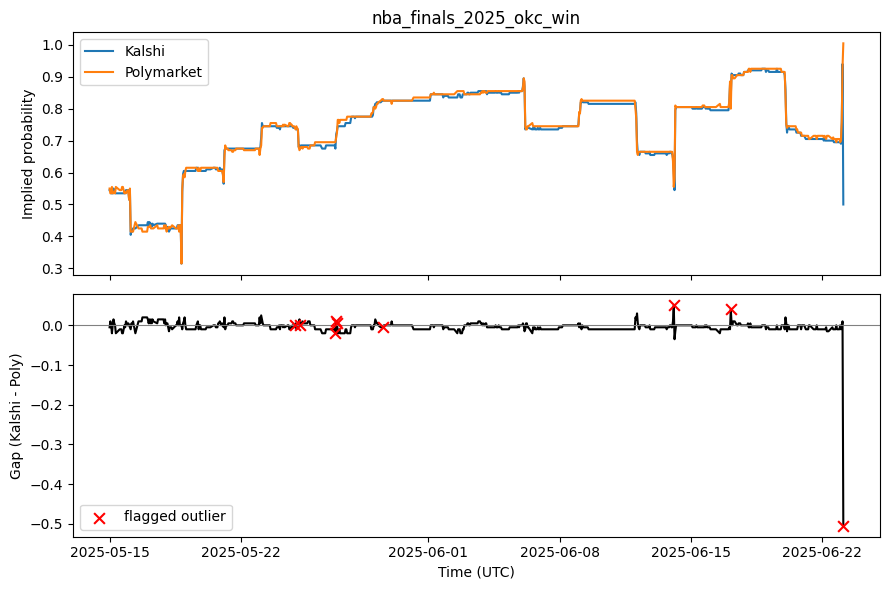

Saved plot to out/nba_finals_2025_okc_win/gap_plot.png
Done: 802 matched observations

=== papal_conclave_2025_prevost (Culture) ===
Kalshi: 244 observations
Polymarket: 390 observations
Aligning markets...
  flagged 5 outlier point(s)


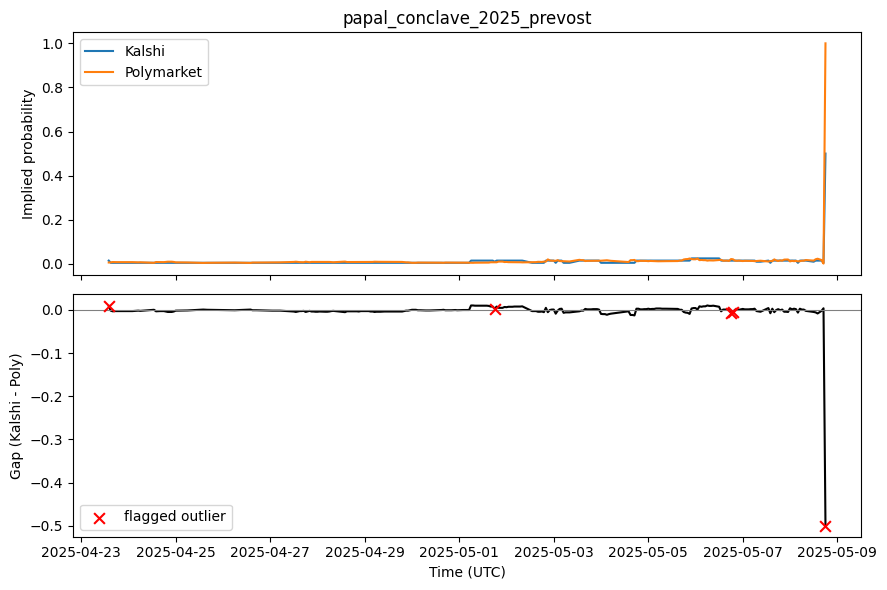

Saved plot to out/papal_conclave_2025_prevost/gap_plot.png
Done: 244 matched observations

=== oscars_2025_anora_best_pic (Culture) ===
Kalshi: 511 observations
Polymarket: 729 observations
Aligning markets...
  flagged 4 outlier point(s)


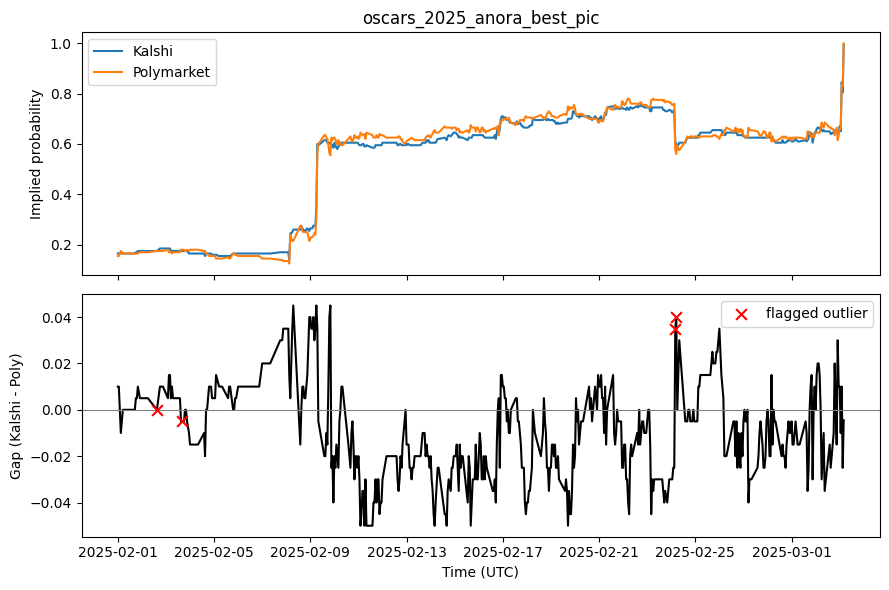

Saved plot to out/oscars_2025_anora_best_pic/gap_plot.png
Done: 511 matched observations

=== taylor_swift_engagement_yes (Culture) ===
Kalshi: 945 observations
Polymarket: 1030 observations
Aligning markets...
  flagged 23 outlier point(s)


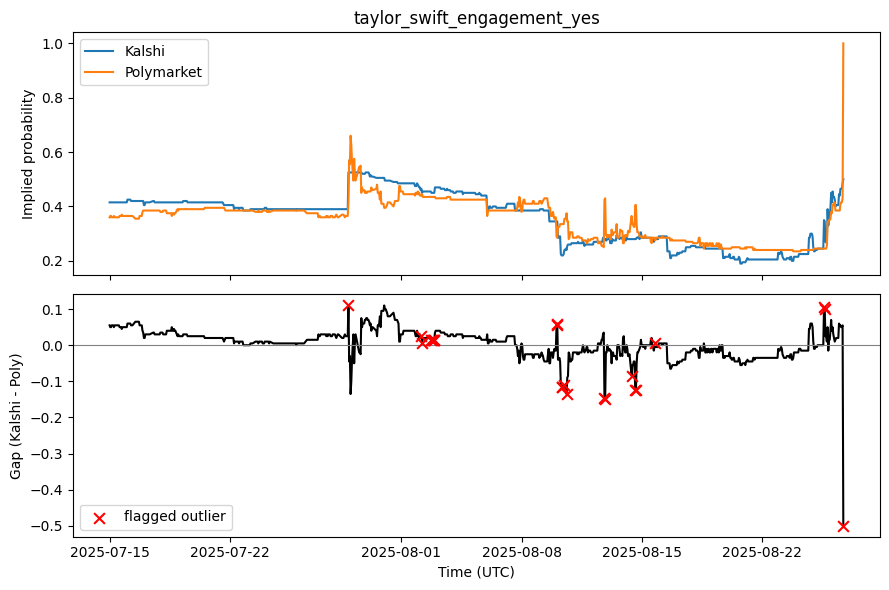

Saved plot to out/taylor_swift_engagement_yes/gap_plot.png
Done: 947 matched observations


,label,category,start,end,kalshi_ticker,poly_token_id,n_points,mean_gap,mean_abs_gap,median_abs_gap,max_abs_gap,gap_std
0,election_2024_DJT_wins,Politics,2024-10-01,2024-11-06,PRES-2024-DJT,2174263314346390629056905015582624153306727273...,609,-0.028487,0.028498,0.0295,0.0665,0.013343
1,fomc_sep2026_hike_25bp,Politics,2026-08-15,2026-09-17,KXFEDDECISION-26SEP-H25,6384252906871000571616932538031547035904774978...,778,0.006877,0.011105,0.0100,0.4100,0.019157
2,shutdown_oct2025_yes,Politics,2025-09-01,2025-10-02,KXGOVSHUT-25OCT01,9804509382243154793836542309578642180445288626...,362,0.007293,0.021740,0.0200,0.1400,0.027621
3,super_bowl_lx_seattle_wins,Sports,2026-01-01,2026-02-10,KXSB-26-SEA,9173793195407946120579274872373095646639843739...,925,0.001698,0.008211,0.0070,0.4995,0.018737
4,world_series_2025_dodgers_win,Sports,2025-10-01,2025-11-05,KXMLB-25-LAD,5005629129637301340305326467244879696155865638...,765,0.008308,0.011588,0.0100,0.4995,0.021504
5,nba_finals_2025_okc_win,Sports,2025-05-15,2025-06-25,KXNBA-25-OKC,8352764492764897083515695000702469032772615861...,802,-0.003946,0.007250,0.0050,0.5045,0.019492
6,papal_conclave_2025_prevost,Culture,2025-04-15,2025-05-10,KXNEXTPOPE-35-RPRE,1138457247000540835617906916045687608996273699...,244,-0.002826,0.005785,0.0030,0.4995,0.032263
7,oscars_2025_anora_best_pic,Culture,2025-02-01,2025-03-03,KXOSCARPIC-25-A,1018044885195187396947687732754809918865343613...,511,-0.009206,0.017895,0.0150,0.0500,0.019850
8,taylor_swift_engagement_yes,Culture,2025-07-15,2025-08-27,KXENGAGEMENTSWIFTKELCE-25,6524354514006048819476744939163302763096035452...,947,0.003332,0.029097,0.0250,0.4995,0.039730


In [18]:
summary_rows = []

for original_event in EVENTS:

    event = resolve_event_ids(original_event)

    label = event["label"]

    print(f"\n=== {label} ({event['category']}) ===")

    # Skip events that still do not have both market identifiers
    if (
        event.get("kalshi_ticker") == "FILL_IN"
        or event.get("poly_token_id") == "FILL_IN"
        or not event.get("kalshi_ticker")
        or not event.get("poly_token_id")
    ):
        print("SKIPPED: missing Kalshi ticker or Polymarket token ID")
        continue

    # Create output folder for this event
    out_dir = Path("out") / label
    out_dir.mkdir(parents=True, exist_ok=True)

    # -------------------------
    # Pull Kalshi data
    # -------------------------
    print("Downloading Kalshi...")

    kalshi_df = get_kalshi_candles(
        ticker=event["kalshi_ticker"],
        start=event["start"],
        end=event["end"],
        period_minutes=DEFAULT_PERIOD_MINUTES
    )

    if kalshi_df.empty:
        print("No Kalshi data found.")
        continue

    # -------------------------
    # Pull Polymarket data
    # -------------------------
    print("Downloading Polymarket...")

    poly_df = get_polymarket_history(
        token_id=event["poly_token_id"],
        start=event["start"],
        end=event["end"],
        fidelity_minutes=DEFAULT_POLY_FIDELITY_MINUTES
    )

    if poly_df.empty:
        print("No Polymarket data found.")
        continue

    # -------------------------
    # Align timestamps + gap
    # -------------------------
    print("Aligning markets...")

    merged = align_and_compute_gap(
        kalshi_df,
        poly_df,
        tolerance="45min"
    )

    if merged.empty:
        print("No aligned observations.")
        continue

    # -------------------------
    # Flag unusual gaps
    # -------------------------
    merged = flag_gap_outliers(merged)

    # -------------------------
    # Save event data
    # -------------------------
    merged.to_csv(
        out_dir / "gap.csv",
        index=False
    )

    plot_gap(
        merged,
        out_dir / "gap_plot.png",
        title=label
    )

    # -------------------------
    # Summary statistics
    # -------------------------
    summary_rows.append({
        "label": label,
        "category": event["category"],
        "start": event["start"],
        "end": event["end"],
        "kalshi_ticker": event["kalshi_ticker"],
        "poly_token_id": event["poly_token_id"],
        "n_points": len(merged),
        "mean_gap": merged["gap"].mean(),
        "mean_abs_gap": merged["gap"].abs().mean(),
        "median_abs_gap": merged["gap"].abs().median(),
        "max_abs_gap": merged["gap"].abs().max(),
        "gap_std": merged["gap"].std(),
    })

    print(f"Done: {len(merged)} matched observations")


# -------------------------
# Combined summary
# -------------------------
summary_df = pd.DataFrame(summary_rows)

if not summary_df.empty:

    summary_df.to_csv(
        Path("out") / "summary.csv",
        index=False
    )

    display(summary_df)

else:
    print("\nNo events were successfully processed.")

## Step 4 — summary table across all events

One row per event: how many aligned points, mean/max gap, and how many
outliers got flagged. Saved as `out/summary.csv`.


In [19]:
Path("out").mkdir(exist_ok=True)
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv("out/summary.csv", index=False)
summary_df


,label,category,start,end,kalshi_ticker,poly_token_id,n_points,mean_gap,mean_abs_gap,median_abs_gap,max_abs_gap,gap_std
0,election_2024_DJT_wins,Politics,2024-10-01,2024-11-06,PRES-2024-DJT,2174263314346390629056905015582624153306727273...,609,-0.028487,0.028498,0.0295,0.0665,0.013343
1,fomc_sep2026_hike_25bp,Politics,2026-08-15,2026-09-17,KXFEDDECISION-26SEP-H25,6384252906871000571616932538031547035904774978...,778,0.006877,0.011105,0.0100,0.4100,0.019157
2,shutdown_oct2025_yes,Politics,2025-09-01,2025-10-02,KXGOVSHUT-25OCT01,9804509382243154793836542309578642180445288626...,362,0.007293,0.021740,0.0200,0.1400,0.027621
3,super_bowl_lx_seattle_wins,Sports,2026-01-01,2026-02-10,KXSB-26-SEA,9173793195407946120579274872373095646639843739...,925,0.001698,0.008211,0.0070,0.4995,0.018737
4,world_series_2025_dodgers_win,Sports,2025-10-01,2025-11-05,KXMLB-25-LAD,5005629129637301340305326467244879696155865638...,765,0.008308,0.011588,0.0100,0.4995,0.021504
5,nba_finals_2025_okc_win,Sports,2025-05-15,2025-06-25,KXNBA-25-OKC,8352764492764897083515695000702469032772615861...,802,-0.003946,0.007250,0.0050,0.5045,0.019492
6,papal_conclave_2025_prevost,Culture,2025-04-15,2025-05-10,KXNEXTPOPE-35-RPRE,1138457247000540835617906916045687608996273699...,244,-0.002826,0.005785,0.0030,0.4995,0.032263
7,oscars_2025_anora_best_pic,Culture,2025-02-01,2025-03-03,KXOSCARPIC-25-A,1018044885195187396947687732754809918865343613...,511,-0.009206,0.017895,0.0150,0.0500,0.019850
8,taylor_swift_engagement_yes,Culture,2025-07-15,2025-08-27,KXENGAGEMENTSWIFTKELCE-25,6524354514006048819476744939163302763096035452...,947,0.003332,0.029097,0.0250,0.4995,0.039730
